# Phase 2: Statistical Baselines

Before I build anything sophisticated, I want to know how well simple models can already do. These baselines set the score that every later model has to beat, so I want them to be honest and well tested.

**The task.** Given what I know about an accident, predict how severe the outcome was: fatality, hospitalized, or not hospitalized.

**The data.** Accident investigation records from the Department of Labor's OSHA enforcement data, prepared in my previous notebook. Each row is one injured worker, with coded circumstances (type of event, source of injury, human factor, task, age and more) and a short written description with outcome words removed.

**What I compare.** I focus on construction accidents, but I also test whether training on accidents from every industry helps. I train three ways and always score on the same construction cases:

1. Construction only, using the strict industry code definition
2. All industries
3. Construction, using the broader definition that adds inspections citing a construction standard

**How I test.** I use cross validation where all rows from the same accident stay on the same side of the split, so the model is never tested on an accident it has partly seen. I also run a split by date as a second check.

**Models.** Two dummy baselines, a simple rule based classifier, Logistic Regression, Ridge Classifier and Naive Bayes. The main metric is macro F1, which treats the three classes equally, so a model cannot look good by ignoring the smallest class.

## 0. Settings

`QUICK_TEST` runs everything on a small sample so I can check that the code works in a couple of minutes. For the real results I set it to `False`. Results are only saved to the database and to the results file when `QUICK_TEST` is `False`.

In [1]:
import sys
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

# ---- settings ----
QUICK_TEST = False      
N_SPLITS = 5
N_REPEATS = 1          # raise to 3 for tighter estimates (takes about 3 times longer)
RANDOM_STATE = 42
TIME_SPLIT_CUTOFF = "2017-01-01"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
FIG = ROOT / "figures"
MODELS = ROOT / "models"
FIG.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)
sys.path.append(str(ROOT / "src"))

print("Project root:", ROOT)
print("QUICK_TEST:", QUICK_TEST)

Project root: c:\Users\sabin\constructiq
QUICK_TEST: False


## 1. Loading the prepared table

This is the table I built in the previous notebook. It has every labeled accident, flags for the two construction definitions, the cleaned text and the two groups of columns.

In [2]:
table = pd.read_csv(PROC / "accidents_labeled_all_industries.csv", low_memory=False)
table["event_date"] = pd.to_datetime(table["event_date"], errors="coerce", utc=True)
table["text_clean"] = table["text_clean"].fillna("")
table = table.reset_index(drop=True)

if QUICK_TEST:
    rng = np.random.default_rng(RANDOM_STATE)
    ids = table["summary_nr"].unique()
    keep_ids = rng.choice(ids, size=min(30000, len(ids)), replace=False)
    table = table[table["summary_nr"].isin(keep_ids)].reset_index(drop=True)
    print("QUICK_TEST sample in use")

LABELS = [1, 2, 3]
LABEL_NAMES = {1: "Fatality", 2: "Hospitalized", 3: "Not hospitalized"}

print("Rows:", len(table), "| accidents:", table["summary_nr"].nunique())
print("Construction strict rows:", int(table["is_construction_strict"].sum()))
print("Construction broad rows:", int(table["is_construction_broad"].sum()))
print(table["severity_3class"].map(LABEL_NAMES).value_counts().to_dict())

Rows: 226291 | accidents: 187074
Construction strict rows: 70979
Construction broad rows: 74523
{'Hospitalized': 99885, 'Fatality': 93068, 'Not hospitalized': 33338}


## 2. Features

I use the circumstance columns only, not the injury detail columns, because injury details are only known after the accident and would make the task easier than the real question. The coded fields are categories, not quantities, so I one hot encode them and group very rare codes together. Age and the building size fields are numbers, so I fill gaps with the median, add a flag for missing values and scale them. The written description becomes TF IDF word features, which downweights common words and keeps the informative ones.

In [3]:
CAT_COLS = ["event_type", "src_of_injury", "evn_factor", "hum_factor", "task_assigned", "occ_code",
            "const_op", "const_op_cause", "const_end_use", "project_cost", "project_type"]
NUM_COLS = ["age", "build_stories", "nonbuild_ht"]
STRUCT_COLS = CAT_COLS + NUM_COLS

for c in CAT_COLS:
    table[c] = table[c].astype(str)

def make_struct():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, dtype=np.float32), CAT_COLS),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), NUM_COLS),
    ])

def make_tfidf():
    return TfidfVectorizer(max_features=20000, min_df=5, stop_words="english",
                           sublinear_tf=True, dtype=np.float32)

print("Structured columns:", STRUCT_COLS)

Structured columns: ['event_type', 'src_of_injury', 'evn_factor', 'hum_factor', 'task_assigned', 'occ_code', 'const_op', 'const_op_cause', 'const_end_use', 'project_cost', 'project_type', 'age', 'build_stories', 'nonbuild_ht']


## 2b. Removing outcome language from the text

My first check showed that the text alone carries almost all of the predictive signal, and the words doing the work describe the outcome, not the circumstances: how the worker was treated, whether they were released, what the examiner found, and the year of the report. A model that reads the outcome in the report is not predicting risk. I remove years and a list of injury, treatment and outcome word stems from the text. This is a best effort, since I cannot remove every hint, so I keep the original text to measure the difference.

In [4]:
OUTCOME_STEMS = (
    r"\b(?:injur\w*|fractur\w*|amputat\w*|paraly\w*|lacerat\w*|contus\w*|sprain\w*|bruis\w*|stitch\w*|"
    r"concuss\w*|dislocat\w*|treat\w*|releas\w*|discharg\w*|requir\w*|underw\w*|undergo\w*|hospitali\w*|"
    r"medical\w*|minor|uninjur\w*|later|scene|arriv\w*|examiner|coroner|autops\w*|complication\w*|"
    r"cardiac|arrest|cpr|resuscitat\w*|unresponsive|lifeless|pulse|massive|internal|blunt|days|weeks|"
    r"months|recover\w*|surviv\w*|condition|critical\w*|serious\w*|severe\w*|sustain\w*|suffer\w*|"
    r"incur\w*|receiv\w*)\b"
)
GLUED_OUTCOME = r"(?:hospitali\w*|killed|admitted|treated|died)"
YEARS = r"\b(?:19|20)\d{2}\b"

table["text_report"] = table["text_clean"]
table["text_clean"] = (table["text_report"]
                       .str.replace(GLUED_OUTCOME, " ", regex=True)
                       .str.replace(YEARS, " ", regex=True)
                       .str.replace(OUTCOME_STEMS, " ", regex=True))
print("Before:", table["text_report"].iloc[0][:300])
print("After: ", table["text_clean"].iloc[0][:300])

Before: employee suffers partial thumb amputation in table saw amputated,guard,slip,thumb,saw,blade,table saw employee #1 was cutting a board on a table saw when his left hand slipped and went under the guard. the blade amputated 1/4 to 1/2 of his left thumb.
After:  employee   partial thumb   in table saw  ,guard,slip,thumb,saw,blade,table saw employee #1 was cutting a board on a table saw when his left hand slipped and went under the guard. the blade   1/4 to 1/2 of his left thumb.


## 3. Models and scoring

For each training set I fit:

- **Dummy, most frequent:** always predicts the most common class
- **Dummy, stratified:** guesses randomly using the training class frequencies
- **Rule based:** for each type of event, predict the most common severity seen in training
- **Logistic Regression and Ridge Classifier:** linear models on the structured features plus the text features, with class weights that make the rare classes count more
- **Naive Bayes:** a probabilistic model on the text only, with equal class priors

Every model predicts one of the three classes. I score the three class result with accuracy and macro F1. I also collapse the same predictions into fatal versus not fatal and score that too, which tells me how well the model separates the most serious outcome.

In [5]:
def score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    per_class = f1_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    yt, yp = (y_true == 1), (y_pred == 1)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "f1_fatal": per_class[0],
        "f1_hospitalized": per_class[1],
        "f1_not_hospitalized": per_class[2],
        "binary_accuracy": accuracy_score(yt, yp),
        "binary_macro_f1": f1_score(yt, yp, average="macro", zero_division=0),
    }

MODEL_ORDER = ["Dummy most frequent", "Dummy stratified", "Rule based (event type)",
               "Logistic Regression", "Ridge Classifier", "Naive Bayes"]

def fit_predict_all(train_df, test_df, seed):
    y_tr = train_df["severity_3class"].to_numpy()
    classes, counts = np.unique(y_tr, return_counts=True)
    majority = classes[counts.argmax()]
    preds = {}

    preds["Dummy most frequent"] = np.full(len(test_df), majority)
    rng = np.random.default_rng(seed)
    preds["Dummy stratified"] = rng.choice(classes, size=len(test_df), p=counts / counts.sum())

    rule = train_df.groupby("event_type")["severity_3class"].agg(lambda s: s.mode().iloc[0])
    preds["Rule based (event type)"] = test_df["event_type"].map(rule).fillna(majority).astype(int).to_numpy()

    struct = make_struct()
    Xs_tr = struct.fit_transform(train_df[STRUCT_COLS])
    Xs_te = struct.transform(test_df[STRUCT_COLS])
    tfidf = make_tfidf()
    T_tr = tfidf.fit_transform(train_df["text_clean"])
    T_te = tfidf.transform(test_df["text_clean"])
    X_tr = sparse.hstack([Xs_tr, T_tr]).tocsr()
    X_te = sparse.hstack([Xs_te, T_te]).tocsr()

    lr = LogisticRegression(max_iter=300, C=1.0, class_weight="balanced")
    preds["Logistic Regression"] = lr.fit(X_tr, y_tr).predict(X_te)

    ridge = RidgeClassifier(alpha=1.0, class_weight="balanced")
    preds["Ridge Classifier"] = ridge.fit(X_tr, y_tr).predict(X_te)

    nb = MultinomialNB(alpha=0.1, fit_prior=False)
    preds["Naive Bayes"] = nb.fit(T_tr, y_tr).predict(T_te)
    return preds

SETUPS = {
    "Construction only (strict)": table["is_construction_strict"].to_numpy(),
    "All industries": np.ones(len(table), dtype=bool),
    "Construction broad": table["is_construction_broad"].to_numpy(),
}
TEST_MASK = table["is_construction_strict"].to_numpy()
print({k: int(v.sum()) for k, v in SETUPS.items()})

{'Construction only (strict)': 70979, 'All industries': 226291, 'Construction broad': 74523}


## 4. Cross validation, keeping each accident together

I split the accidents into folds, stratified by severity so each fold has a similar class mix. All rows from one accident land in the same fold. In each fold I test only on construction cases, while the training set depends on the setup: construction only, all industries, or the broad construction definition. The folds are the same for all three setups, so the comparison is fair.

In [6]:
fold_rows = []
oof = {}   # (setup, model) -> lists of true labels, predictions, accident ids

start = time.time()
for rep in range(N_REPEATS):
    sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE + rep)
    for fold, (tr_idx, te_idx) in enumerate(sgkf.split(table, table["severity_3class"], groups=table["summary_nr"])):
        te_pos = te_idx[TEST_MASK[te_idx]]
        test_df = table.iloc[te_pos]
        for setup, mask in SETUPS.items():
            tr_pos = tr_idx[mask[tr_idx]]
            train_df = table.iloc[tr_pos]
            preds = fit_predict_all(train_df, test_df, seed=RANDOM_STATE + rep * 100 + fold)
            for model in MODEL_ORDER:
                m = score(test_df["severity_3class"], preds[model])
                m.update({"setup": setup, "model": model, "repeat": rep, "fold": fold,
                          "train_rows": len(train_df), "test_rows": len(test_df)})
                fold_rows.append(m)
                bucket = oof.setdefault((setup, model), {"y": [], "p": [], "g": []})
                bucket["y"].append(test_df["severity_3class"].to_numpy())
                bucket["p"].append(np.asarray(preds[model]))
                bucket["g"].append(test_df["summary_nr"].to_numpy())
        print(f"repeat {rep} fold {fold} done | elapsed {(time.time() - start) / 60:.1f} min")

fold_df = pd.DataFrame(fold_rows)
print("Finished in", round((time.time() - start) / 60, 1), "minutes")

repeat 0 fold 0 done | elapsed 3.6 min
repeat 0 fold 1 done | elapsed 6.4 min
repeat 0 fold 2 done | elapsed 9.8 min
repeat 0 fold 3 done | elapsed 13.3 min
repeat 0 fold 4 done | elapsed 16.7 min
Finished in 16.7 minutes


## 5. Results

The table shows the average over the folds, with the standard deviation across folds in the spread column. Rows are grouped by training setup, and every score is measured on construction cases only.

In [7]:
METRICS = ["accuracy", "macro_f1", "binary_accuracy", "binary_macro_f1"]

summary = fold_df.groupby(["setup", "model"])[METRICS].agg(["mean", "std"])
summary.columns = [f"{a}_{b}" for a, b in summary.columns]
summary = summary.reset_index()
summary["model"] = pd.Categorical(summary["model"], MODEL_ORDER, ordered=True)
summary = summary.sort_values(["setup", "model"]).reset_index(drop=True)

show = summary[["setup", "model", "accuracy_mean", "macro_f1_mean", "macro_f1_std",
                "binary_accuracy_mean", "binary_macro_f1_mean"]].round(3)
show.columns = ["setup", "model", "accuracy", "macro F1", "macro F1 spread", "fatal vs not: accuracy", "fatal vs not: macro F1"]
show

,setup,model,accuracy,macro F1,macro F1 spread,fatal vs not: accuracy,fatal vs not: macro F1
0,All industries,Dummy most frequent,0.429,0.200,0.001,0.526,0.345
1,All industries,Dummy stratified,0.402,0.334,0.002,0.507,0.500
2,All industries,Rule based (event type),0.508,0.351,0.002,0.577,0.561
3,All industries,Logistic Regression,0.725,0.630,0.006,0.827,0.827
4,All industries,Ridge Classifier,0.725,0.625,0.005,0.818,0.817
5,All industries,Naive Bayes,0.677,0.549,0.013,0.744,0.742
6,Construction broad,Dummy most frequent,0.474,0.214,0.001,0.474,0.322
7,Construction broad,Dummy stratified,0.422,0.336,0.001,0.504,0.503
8,Construction broad,Rule based (event type),0.525,0.368,0.002,0.578,0.576
9,Construction broad,Logistic Regression,0.702,0.620,0.010,0.828,0.828


In [8]:
# Does training on more industries help? Macro F1 by setup for the trained models
pivot = summary[summary["model"].isin(["Logistic Regression", "Ridge Classifier", "Naive Bayes"])].pivot(
    index="model", columns="setup", values="macro_f1_mean").round(3)
pivot

setup,All industries,Construction broad,Construction only (strict)
model,,,
Logistic Regression,0.630,0.620,0.619
Ridge Classifier,0.625,0.611,0.611
Naive Bayes,0.549,0.560,0.560


## 6. Per class results and confusion matrices

Macro F1 hides which class a model gets wrong. For the best trained model in each setup I show the F1 score for each class and the confusion matrix built from the predictions on all the held out folds. Each row of the matrix shows what share of the true cases of that class the model assigned to each outcome.

In [9]:
TRAINED = ["Logistic Regression", "Ridge Classifier", "Naive Bayes"]
best = {}
for setup in SETUPS:
    sub = summary[(summary["setup"] == setup) & (summary["model"].isin(TRAINED))]
    best[setup] = str(sub.sort_values("macro_f1_mean", ascending=False).iloc[0]["model"])
print("Best trained model per setup:", best)
print()

per_class = fold_df.groupby(["setup", "model"])[["f1_fatal", "f1_hospitalized", "f1_not_hospitalized"]].mean().round(3)
print(per_class.loc[[(s, m) for s, m in best.items()]])

Best trained model per setup: {'Construction only (strict)': 'Logistic Regression', 'All industries': 'Logistic Regression', 'Construction broad': 'Logistic Regression'}

                                                f1_fatal  f1_hospitalized  f1_not_hospitalized
setup                      model                                                              
Construction only (strict) Logistic Regression     0.821            0.677                0.360
All industries             Logistic Regression     0.827            0.698                0.365
Construction broad         Logistic Regression     0.820            0.679                0.361


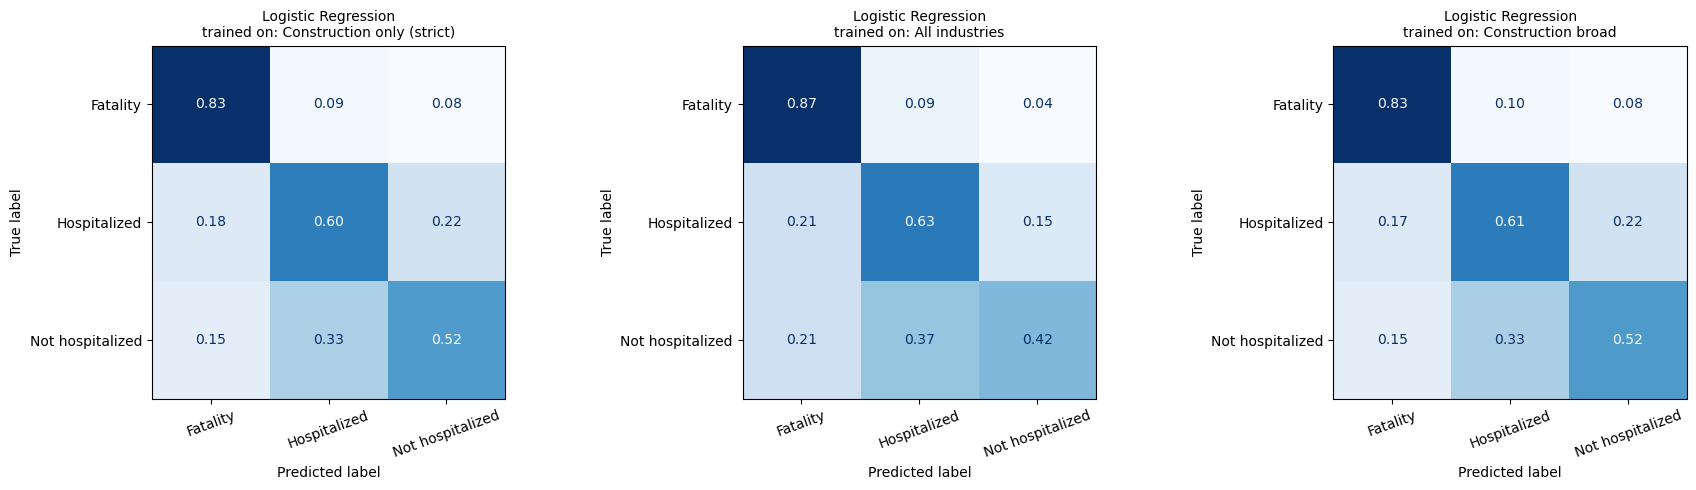

In [10]:
fig, axes = plt.subplots(1, len(SETUPS), figsize=(6 * len(SETUPS), 5))
for ax, (setup, model) in zip(np.atleast_1d(axes), best.items()):
    b = oof[(setup, model)]
    y, p = np.concatenate(b["y"]), np.concatenate(b["p"])
    ConfusionMatrixDisplay.from_predictions(
        y, p, labels=LABELS, display_labels=[LABEL_NAMES[l] for l in LABELS],
        normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{model}\ntrained on: {setup}", fontsize=10)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(FIG / "baseline_confusion_matrices.png", dpi=150)
plt.show()

## 7. How certain are these scores?

Averages over a few folds do not show how much a score could move. For the best model in each setup I resample accidents with replacement 500 times and recompute macro F1 each time. Resampling whole accidents, not single rows, respects the fact that some accidents have several injured workers. The range between the 2.5th and 97.5th percentiles is a 95 percent confidence interval.

In [11]:
def macro_f1_from_cm(cm):
    tp = np.diag(cm)
    denom = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0).mean()

def group_bootstrap_ci(y_true, y_pred, groups, n_boot=500, seed=RANDOM_STATE):
    codes = (y_true - 1) * 3 + (y_pred - 1)
    g_codes, g_index = pd.factorize(groups)
    contrib = np.zeros((len(g_index), 9))
    np.add.at(contrib, (g_codes, codes), 1)
    rng = np.random.default_rng(seed)
    n = len(g_index)
    vals = []
    for _ in range(n_boot):
        w = rng.multinomial(n, np.full(n, 1.0 / n))
        vals.append(macro_f1_from_cm((w @ contrib).reshape(3, 3)))
    return np.percentile(vals, [2.5, 97.5])

ci_rows = []
for setup, model in best.items():
    b = oof[(setup, model)]
    y, p, g = np.concatenate(b["y"]), np.concatenate(b["p"]), np.concatenate(b["g"])
    lo, hi = group_bootstrap_ci(y, p, g)
    ci_rows.append({"setup": setup, "model": model, "macro_f1": round(macro_f1_from_cm(
        np.bincount((y - 1) * 3 + (p - 1), minlength=9).reshape(3, 3)), 3),
        "ci_low": round(lo, 3), "ci_high": round(hi, 3)})

ci_table = pd.DataFrame(ci_rows)
ci_table

,setup,model,macro_f1,ci_low,ci_high
0,Construction only (strict),Logistic Regression,0.62,0.613,0.626
1,All industries,Logistic Regression,0.63,0.623,0.637
2,Construction broad,Logistic Regression,0.62,0.614,0.627


## 8. A second check: split by date

Cross validation mixes years together. A date split is closer to real use, where a model trained on the past is asked about the future. I train on accidents before the cutoff date and test on construction accidents on or after it. Reporting practices and the mix of outcomes shifted over the decades, so I expect these scores to be lower and I treat this as a stress test, not the headline number.

In [12]:
cutoff = pd.Timestamp(TIME_SPLIT_CUTOFF, tz="UTC")
before = (table["event_date"] < cutoff).to_numpy()
after = (table["event_date"] >= cutoff).to_numpy()

test_pos = np.where(after & TEST_MASK)[0]
test_df = table.iloc[test_pos]
print("Test period starts:", TIME_SPLIT_CUTOFF, "| test rows:", len(test_df))
print("Test classes:", test_df["severity_3class"].map(LABEL_NAMES).value_counts().to_dict())

time_rows = []
for setup, mask in SETUPS.items():
    train_df = table.iloc[np.where(before & mask)[0]]
    print(setup, "| train rows:", len(train_df),
          "| train classes:", train_df["severity_3class"].map(LABEL_NAMES).value_counts().to_dict())
    preds = fit_predict_all(train_df, test_df, seed=RANDOM_STATE)
    for model in MODEL_ORDER:
        m = score(test_df["severity_3class"], preds[model])
        m.update({"setup": setup, "model": model})
        time_rows.append(m)

time_df = pd.DataFrame(time_rows)
time_df[["setup", "model", "accuracy", "macro_f1", "binary_accuracy", "binary_macro_f1"]].round(3)

Test period starts: 2017-01-01 | test rows: 12960
Test classes: {'Hospitalized': 7100, 'Fatality': 4959, 'Not hospitalized': 901}
Construction only (strict) | train rows: 47826 | train classes: {'Fatality': 22563, 'Hospitalized': 20305, 'Not hospitalized': 4958}
All industries | train rows: 138138 | train classes: {'Hospitalized': 59591, 'Fatality': 58072, 'Not hospitalized': 20475}
Construction broad | train rows: 49743 | train classes: {'Fatality': 23796, 'Hospitalized': 20785, 'Not hospitalized': 5162}


,setup,model,accuracy,macro_f1,binary_accuracy,binary_macro_f1
0,Construction only (strict),Dummy most frequent,0.383,0.184,0.383,0.277
1,Construction only (strict),Dummy stratified,0.425,0.330,0.508,0.498
2,Construction only (strict),Rule based (event type),0.531,0.356,0.562,0.543
3,Construction only (strict),Logistic Regression,0.647,0.547,0.712,0.711
4,Construction only (strict),Ridge Classifier,0.665,0.575,0.739,0.739
5,Construction only (strict),Naive Bayes,0.716,0.602,0.804,0.794
6,All industries,Dummy most frequent,0.548,0.236,0.617,0.382
7,All industries,Dummy stratified,0.408,0.323,0.518,0.499
8,All industries,Rule based (event type),0.548,0.379,0.605,0.555
9,All industries,Logistic Regression,0.657,0.565,0.715,0.715


## 9. Saving the results

I save the cross validation results to a results file and to the `model_results` table in PostgreSQL, so every later phase can compare against these numbers. The code reads the table's own columns and only fills the ones that exist. It also clears earlier Phase 2 rows first so rerunning does not create duplicates. Nothing is saved while `QUICK_TEST` is on.

In [13]:
results_out = summary.copy()
results_out["phase"] = "Phase 2"
results_out["validation"] = f"grouped {N_SPLITS} fold cross validation, {N_REPEATS} repeat(s), test on strict construction cases"

if QUICK_TEST:
    print("QUICK_TEST is on, so nothing is saved. Set QUICK_TEST = False for the real run.")
else:
    results_out.to_csv(MODELS / "results_table.csv", index=False)
    print("Saved:", MODELS / "results_table.csv")

    from db import get_db
    with get_db() as conn:
        with conn.cursor() as cur:
            cur.execute("SELECT column_name, data_type FROM information_schema.columns "
                        "WHERE table_name = 'model_results' ORDER BY ordinal_position;")
            cols = {name: dtype for name, dtype in cur.fetchall()}
            print("model_results columns:", cols)

            needed = {"model_name", "accuracy", "macro_f1"}
            if not needed.issubset(cols):
                raise RuntimeError(f"model_results is missing columns {needed - set(cols)}")

            phase_value = 2 if cols.get("phase") in ("integer", "smallint", "bigint") else "Phase 2"
            if "phase" in cols:
                cur.execute("DELETE FROM model_results WHERE phase = %s", (phase_value,))

            inserted = 0
            for _, r in summary.iterrows():
                row = {
                    "phase": phase_value,
                    "model_name": f"{r['model']} | {r['setup']}",
                    "accuracy": float(r["accuracy_mean"]),
                    "macro_f1": float(r["macro_f1_mean"]),
                    "notes": (f"Grouped {N_SPLITS} fold CV, macro F1 spread {r['macro_f1_std']:.3f}, "
                              f"fatal vs not macro F1 {r['binary_macro_f1_mean']:.3f}, test on strict construction cases"),
                }
                row = {k: v for k, v in row.items() if k in cols}
                names = ", ".join(row)
                marks = ", ".join(["%s"] * len(row))
                cur.execute(f"INSERT INTO model_results ({names}) VALUES ({marks})", list(row.values()))
                inserted += 1
            print("Inserted rows:", inserted)

Saved: c:\Users\sabin\constructiq\models\results_table.csv
model_results columns: {'id': 'integer', 'phase': 'character varying', 'model_name': 'character varying', 'accuracy': 'double precision', 'macro_f1': 'double precision', 'notes': 'text', 'created_at': 'timestamp without time zone'}
Inserted rows: 18


## 10. Where does the signal come from?

The models do well, and I want to understand why before I trust the number. I repeat the cross validation for Logistic Regression, trained on construction accidents only, using the same folds as before, with three feature sets: the structured circumstance columns only, the text only, and both together. If the text alone does almost all of the work, then my score depends heavily on how the accident was written up, not only on the circumstances.

In [14]:
ablation_rows = []
strict_mask = SETUPS["Construction only (strict)"]
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

start = time.time()
for fold, (tr_idx, te_idx) in enumerate(sgkf.split(table, table["severity_3class"], groups=table["summary_nr"])):
    te_pos = te_idx[TEST_MASK[te_idx]]
    tr_pos = tr_idx[strict_mask[tr_idx]]
    train_df, test_df = table.iloc[tr_pos], table.iloc[te_pos]
    y_tr = train_df["severity_3class"].to_numpy()

    struct = make_struct()
    Xs_tr = struct.fit_transform(train_df[STRUCT_COLS])
    Xs_te = struct.transform(test_df[STRUCT_COLS])
    tfidf = make_tfidf()
    T_tr = tfidf.fit_transform(train_df["text_clean"])
    T_te = tfidf.transform(test_df["text_clean"])
    tfidf_r = make_tfidf()
    R_tr = tfidf_r.fit_transform(train_df["text_report"])
    R_te = tfidf_r.transform(test_df["text_report"])

    views = {
        "Structured columns only": (Xs_tr, Xs_te),
        "Event text only": (T_tr, T_te),
        "Both (event text)": (sparse.hstack([Xs_tr, T_tr]).tocsr(), sparse.hstack([Xs_te, T_te]).tocsr()),
        "Report text only (keeps outcome language)": (R_tr, R_te),
    }
    for name, (A, B) in views.items():
        lr = LogisticRegression(max_iter=300, C=1.0, class_weight="balanced").fit(A, y_tr)
        m = score(test_df["severity_3class"], lr.predict(B))
        m.update({"features": name, "fold": fold})
        ablation_rows.append(m)
    print(f"fold {fold} done | elapsed {(time.time() - start) / 60:.1f} min")

ablation = pd.DataFrame(ablation_rows)
order = ["Structured columns only", "Event text only", "Both (event text)", "Report text only (keeps outcome language)"]
ablation.groupby("features")[
    ["accuracy", "macro_f1", "f1_fatal", "f1_hospitalized", "f1_not_hospitalized", "binary_accuracy"]].mean().round(3).loc[order]

fold 0 done | elapsed 2.2 min
fold 1 done | elapsed 3.0 min
fold 2 done | elapsed 3.7 min
fold 3 done | elapsed 4.4 min
fold 4 done | elapsed 5.1 min


,accuracy,macro_f1,f1_fatal,f1_hospitalized,f1_not_hospitalized,binary_accuracy
features,,,,,,
Structured columns only,0.538,0.482,0.655,0.520,0.272,0.688
Event text only,0.702,0.610,0.811,0.665,0.354,0.809
Both (event text),0.702,0.619,0.821,0.677,0.360,0.828
Report text only (keeps outcome language),0.779,0.692,0.871,0.754,0.450,0.870


## 11. Which words drive the predictions?

A model that works for the wrong reasons is not a good baseline. To check, I fit a Logistic Regression on the text of the construction accidents and list the words that push a prediction most strongly toward each outcome. This fit is only for inspection, not for scoring. I am looking for words that describe what happened, such as a fall from height, versus words that describe the aftermath, such as how the worker was found.

In [15]:
inspect_df = table[strict_mask]
tfidf_all = make_tfidf()
T_all = tfidf_all.fit_transform(inspect_df["text_clean"])
lr_text = LogisticRegression(max_iter=300, C=1.0, class_weight="balanced").fit(T_all, inspect_df["severity_3class"])
names = np.array(tfidf_all.get_feature_names_out())

for i, cls in enumerate(lr_text.classes_):
    top = np.argsort(lr_text.coef_[i])[::-1][:25]
    print(LABEL_NAMES[cls].upper())
    print(", ".join(names[top]))
    print()

FATALITY
electrocuted, killing, asphyxiated, crushed, heart, drown, cause, result, trauma, apparently, suffocated, causes, drowning, electrocution, stroke, force, instantly, pulmonary, crushing, artery, engulfed, life, head, drowned, lying

HOSPITALIZED
leg, pelvis, vertebra, multiple, ankle, hip, unspecified, femur, jaw, ribs, ca, wrist, bones, remains, services, remember, rib, burns, surgical, arm, lung, vertebrae, ankles, fingers, lumbar

NOT HOSPITALIZED
finger, did, employees, abrasions, cuts, fingertip, strains, taken, day, examined, observation, thumb, ankle, nonserious, sore, abrasion, hours, strain, soreness, wrist, rode, refused, slightly, ppm, partial



## 12. Saving the three tiers of results

The ablation shows three levels of difficulty. Structured circumstances alone are the strictest test of predicting risk. Event text with outcome language removed is an early triage setting. The full report text reads the outcome, so I treat it as a ceiling, not a fair baseline. I save all of them to the database so later phases can compare against the right tier.

In [16]:
if QUICK_TEST:
    print("QUICK_TEST is on, so nothing is saved.")
else:
    from db import get_db
    tiers = ablation.groupby("features")[["accuracy", "macro_f1"]].mean()
    spread = ablation.groupby("features")["macro_f1"].std()
    with get_db() as conn:
        with conn.cursor() as cur:
            cur.execute("DELETE FROM model_results WHERE phase = %s AND model_name LIKE %s",
                        ("Phase 2", "% | features:%"))
            for name, r in tiers.iterrows():
                cur.execute(
                    "INSERT INTO model_results (phase, model_name, accuracy, macro_f1, notes) VALUES (%s, %s, %s, %s, %s)",
                    ("Phase 2", f"Logistic Regression | features: {name}", float(r["accuracy"]), float(r["macro_f1"]),
                     f"Grouped {N_SPLITS} fold CV, construction only training, macro F1 spread {spread[name]:.3f}, test on strict construction cases"))
    print("Inserted", len(tiers), "tier rows")

Inserted 4 tier rows


## What these baselines tell me

**The floor.** A model that always guesses the most common class scores a macro F1 of 0.21. Guessing at random by class frequency gives 0.34, and a simple rule that predicts the usual outcome for each type of event gives 0.37. Any real model has to clear these.

**What simple models achieve.** Logistic Regression, trained on construction accidents and tested on construction accidents it has not seen, reaches a macro F1 of 0.62 and 70 percent accuracy. Ridge Classifier is close at 0.61, and Naive Bayes, which only reads the text, reaches 0.56. When I collapse the same predictions into fatal versus not fatal, accuracy is 83 percent.

**Which outcomes are hard.** The F1 score is 0.82 for fatal cases and 0.68 for hospitalized cases, but only 0.36 for cases where the worker was not hospitalized. That class is the smallest and looks the most like the others, so it is where a better model has the most to gain.

**Does more data from other industries help?** A little. Training on every industry raises Logistic Regression from 0.619 to 0.630 on construction cases. The confidence intervals (0.613 to 0.626 against 0.623 to 0.637) nearly touch, so I treat this as a small gain, not a clear win. Adding inspections that cited a construction standard changed almost nothing.

**Where the signal comes from.** This matters most for how I read the scores:

| Features | Macro F1 |
|---|---|
| Circumstance columns only (event type, source, human factor, task, age, project details) | 0.48 |
| Event text with outcome language removed | 0.61 |
| Circumstances and event text together | 0.62 |
| Full report text, keeping outcome language | 0.69 |

The full report scores highest because it describes how the accident ended, so I do not treat it as a fair baseline. The event text still contains some injury detail, such as body parts and types of injury, which explains why it beats the circumstance columns alone. The honest reading is that circumstances alone give 0.48, and a report written during the early stage of an investigation gives about 0.62.

**A harder test: predicting the future.** When I train on accidents before 2017 and test on construction accidents from 2017 onward, scores fall to between 0.55 and 0.60, and the best model changes (Naive Bayes on construction only data scores 0.60, Logistic Regression 0.55). Reporting practices and the mix of outcomes shifted over the decades, so the future does not look exactly like the past. This test was a single run, so I treat the differences between models here as suggestive, not settled.

**Limits I want to be clear about.** The labels come from OSHA investigation records, which are not a random sample of all construction injuries. Construction is defined by industry codes, so a few accidents may be misclassified. Cleaning the text of outcome words is a best effort, and some hints almost certainly remain.

**The bar for later phases.** Tree based models in the next phase have to beat a macro F1 of 0.62 on the same construction cases with the same folds, and I will compare circumstance only models against 0.48.

In [18]:
from db import get_db

with get_db() as conn:
    with conn.cursor() as cur:
        cur.execute(
            "SELECT model_name, ROUND(accuracy::numeric, 3), ROUND(macro_f1::numeric, 3) "
            "FROM model_results WHERE phase = 'Phase 2' ORDER BY macro_f1 DESC;"
        )
        rows = cur.fetchall()

print(len(rows), "Phase 2 rows in model_results")
pd.DataFrame(rows, columns=["model_name", "accuracy", "macro_f1"])

22 Phase 2 rows in model_results


,model_name,accuracy,macro_f1
0,Logistic Regression | features: Report text on...,0.779,0.692
1,Logistic Regression | All industries,0.725,0.630
2,Ridge Classifier | All industries,0.725,0.625
3,Logistic Regression | Construction broad,0.702,0.620
4,Logistic Regression | Construction only (strict),0.702,0.619
5,Logistic Regression | features: Both (event text),0.702,0.619
6,Ridge Classifier | Construction broad,0.698,0.611
7,Ridge Classifier | Construction only (strict),0.698,0.611
8,Logistic Regression | features: Event text only,0.702,0.610
9,Naive Bayes | Construction only (strict),0.647,0.560
